Judul : Analisis Performa OpenAI Whisper dan BART-Base dalam Transkripsi serta Perangkuman Otomatis pada Narasi Podcast Berbahasa Indonesia Non-Formal

In [ ]:
!pip install faster-whisper yt-dlp transformers sentencepiece \
             jiwer rouge-score pandas matplotlib seaborn torch \
             bert-score --quiet
!apt-get install -y ffmpeg -q

Reading package lists...
Building dependency tree...
Reading state information...
ffmpeg is already the newest version (7:4.4.2-0ubuntu0.22.04.1).
0 upgraded, 0 newly installed, 0 to remove and 42 not upgraded.


In [ ]:
import os
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

BASE_PATH = "/content/drive/MyDrive/NLP_SatuPersen"
dirs = ["audio", "transcript", "summary", "ground_truth_caption", "plots", "results"]
paths = {d: os.path.join(BASE_PATH, d) for d in dirs}
for p in paths.values():
    os.makedirs(p, exist_ok=True)
    print(f"   {p}")

EPISODES = [
    ("https://youtu.be/-3QJLGI7wtI", "ep_01"), ("https://youtu.be/qtJMh1T4aPk", "ep_02"),
    ("https://youtu.be/Sep_ArXpTBk", "ep_03"), ("https://youtu.be/sPbADTfwzwQ", "ep_04"),
    ("https://youtu.be/TICaHFeOlC8", "ep_05"), ("https://youtu.be/YnJJE1qr82s", "ep_06"),
    ("https://youtu.be/8cdZ3rHTT9s", "ep_07"), ("https://youtu.be/1n3VBu4UiyA", "ep_08"),
    ("https://youtu.be/9dbLrJGbtnM", "ep_09"), ("https://youtu.be/t1dOKAYT-tI", "ep_10"),
    ("https://youtu.be/aioplDDKksI", "ep_11"), ("https://youtu.be/WoXaqFyeesE", "ep_12"),
    ("https://youtu.be/Kht7CwxhY4o", "ep_13"), ("https://youtu.be/w8_xj4mxDV4", "ep_14"),
    ("https://youtu.be/Ywunk44CQ6c", "ep_15"), ("https://youtu.be/PDE4q5tt46c", "ep_16"),
    ("https://youtu.be/eMHcVu0ApQw", "ep_17"), ("https://youtu.be/ClEN5Nqlfug", "ep_18"),
    ("https://youtu.be/n3FKik00PdI", "ep_19"), ("https://youtu.be/fqSMPmP971M", "ep_20"),
    ("https://youtu.be/dgsJWx4aL9o", "ep_21"), ("https://youtu.be/gG_3jAA_Ih0", "ep_22"),
    ("https://youtu.be/tRBcaDP7doY", "ep_23"), ("https://youtu.be/dut2nJ4qZ0U", "ep_24"),
    ("https://youtu.be/koenre9fAWs", "ep_25"), ("https://youtu.be/fK0EgoApmOc", "ep_26"),
    ("https://youtu.be/zdXUI2xXLmA", "ep_27"), ("https://youtu.be/iBm0FxRmMpU", "ep_28"),
    ("https://youtu.be/V1PGLRkmOjc", "ep_29"), ("https://youtu.be/lJJQ9OO73p4", "ep_30"),
    ("https://youtu.be/nOoEhJ3ng5E", "ep_31"), ("https://youtu.be/N6h0xa9-gqQ", "ep_32"),
    ("https://youtu.be/yBauVam1Tzw", "ep_33"), ("https://youtu.be/BcC6Sqc_PJY", "ep_34"),
    ("https://youtu.be/BnFOFWPtxEA", "ep_35"), ("https://youtu.be/PzANp7betXs", "ep_36"),
    ("https://youtu.be/C_LpJ1LKk8E", "ep_37"), ("https://youtu.be/LIy1Po30XWI", "ep_38"),
    ("https://youtu.be/dkQX1NUE1nw", "ep_39"), ("https://youtu.be/ws8xdX9HefU", "ep_40"),
]

print(f"\n Setup selesai! {len(EPISODES)} episode terdaftar.")

Mounted at /content/drive
   /content/drive/MyDrive/NLP_SatuPersen/audio
   /content/drive/MyDrive/NLP_SatuPersen/transcript
   /content/drive/MyDrive/NLP_SatuPersen/summary
   /content/drive/MyDrive/NLP_SatuPersen/ground_truth_caption
   /content/drive/MyDrive/NLP_SatuPersen/plots
   /content/drive/MyDrive/NLP_SatuPersen/results

 Setup selesai! 40 episode terdaftar.


Scraping/Data Collection & Unduh Audio dari Youtube

In [ ]:
import yt_dlp
import time

def download_audio_and_caption(url, ep_id):
    """Download audio MP3 + subtitle Indonesia dari YouTube."""
    audio_path = os.path.join(paths['audio'], f"{ep_id}.mp3")
    caption_path = os.path.join(paths['ground_truth_caption'], f"{ep_id}.txt")

    if not os.path.exists(audio_path):
        ydl_opts_audio = {
            'format': 'bestaudio/best',
            'outtmpl': os.path.join(paths['audio'], f"{ep_id}.%(ext)s"),
            'postprocessors': [{
                'key': 'FFmpegExtractAudio',
                'preferredcodec': 'mp3',
                'preferredquality': '128'
            }],
            'quiet': True, 'no_warnings': True
        }
        try:
            with yt_dlp.YoutubeDL(ydl_opts_audio) as ydl:
                ydl.download([url])
            print(f"     Audio OK")
        except Exception as e:
            print(f"     Audio gagal: {e}")
            return False
    else:
        print(f"    ⏭  Audio sudah ada")

    if not os.path.exists(caption_path):
        tmp_dir = f"/tmp/caption_{ep_id}"
        os.makedirs(tmp_dir, exist_ok=True)
        ydl_opts_sub = {
            'skip_download': True,
            'writeautomaticsub': True,
            'writesubtitles': True,
            'subtitleslangs': ['id', 'id-ID'],
            'subtitlesformat': 'vtt',
            'outtmpl': os.path.join(tmp_dir, f"{ep_id}.%(ext)s"),
            'quiet': True, 'no_warnings': True
        }
        try:
            with yt_dlp.YoutubeDL(ydl_opts_sub) as ydl:
                ydl.download([url])

            vtt_files = [f for f in os.listdir(tmp_dir) if f.endswith('.vtt')]
            if vtt_files:
                import re
                with open(os.path.join(tmp_dir, vtt_files[0]), 'r', encoding='utf-8') as vf:
                    vtt_content = vf.read()

                lines = vtt_content.split('\n')
                text_lines = []
                for line in lines:
                    line = line.strip()
                    if (line.startswith('WEBVTT') or
                        '-->' in line or
                        line == '' or
                        re.match(r'^\d+$', line)):
                        continue
                    line = re.sub(r'<[^>]+>', '', line)
                    line = line.strip()
                    if line:
                        text_lines.append(line)

                seen = set()
                unique_lines = []
                for ln in text_lines:
                    if ln not in seen:
                        seen.add(ln)
                        unique_lines.append(ln)

                caption_text = ' '.join(unique_lines)
                with open(caption_path, 'w', encoding='utf-8') as cf:
                    cf.write(caption_text)
                print(f"     Caption OK ({len(caption_text.split())} kata)")
            else:
                print(f"      Tidak ada subtitle ID tersedia")
                with open(caption_path, 'w', encoding='utf-8') as cf:
                    cf.write('')
        except Exception as e:
            print(f"      Caption gagal (akan di-skip dari WER eval): {e}")
    else:
        print(f"      Caption sudah ada")

    return os.path.exists(audio_path)

print(" Memulai download audio + caption...\n")
success_count = 0

for idx, (url, ep_id) in enumerate(EPISODES):
    print(f"[{idx+1:02d}/{len(EPISODES)}] {ep_id}")
    ok = download_audio_and_caption(url, ep_id)
    if ok:
        success_count += 1
    time.sleep(1.5)

print(f"\n Download selesai: {success_count}/{len(EPISODES)} audio berhasil")

 Memulai download audio + caption...

[01/40] ep_01
     Audio OK
     Caption OK (4255 kata)
[02/40] ep_02
     Audio OK
     Caption OK (2212 kata)
[03/40] ep_03
     Audio OK
     Caption OK (2108 kata)
[04/40] ep_04
     Audio OK
     Caption OK (3447 kata)
[05/40] ep_05
     Audio OK
     Caption OK (4116 kata)
[06/40] ep_06
     Audio OK
     Caption OK (2367 kata)
[07/40] ep_07
     Audio OK
     Caption OK (1549 kata)
[08/40] ep_08
     Audio OK
     Caption OK (2284 kata)
[09/40] ep_09
     Audio OK
     Caption OK (1771 kata)
[10/40] ep_10
     Audio OK
     Caption OK (1525 kata)
[11/40] ep_11
     Audio OK
     Caption OK (2703 kata)
[12/40] ep_12
     Audio OK
     Caption OK (3274 kata)
[13/40] ep_13
     Audio OK
     Caption OK (3347 kata)
[14/40] ep_14
     Audio OK
     Caption OK (2484 kata)
[15/40] ep_15
     Audio OK
     Caption OK (3193 kata)
[16/40] ep_16
     Audio OK
     Caption OK (2019 kata)
[17/40] ep_17
     Audio OK
     Caption OK (2592 kata)
[18/40] ep

Load Model Whisper

In [ ]:
from faster_whisper import WhisperModel
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
compute = "float16" if device == "cuda" else "int8"
print(f"  Device: {device.upper()} | Compute type: {compute}")

print("\n⏳ Memuat Whisper small...")
model_small = WhisperModel("small", device=device, compute_type=compute)
print(" Whisper small siap")

print("\n⏳ Memuat Whisper medium...")
model_medium = WhisperModel("medium", device=device, compute_type=compute)
print(" Whisper medium siap")

  Device: CUDA | Compute type: float16

⏳ Memuat Whisper small...
 Whisper small siap

⏳ Memuat Whisper medium...
 Whisper medium siap


Benchmarking Waktu

In [ ]:
import time
import subprocess
import pandas as pd

def get_audio_duration(file_path):
    """Dapatkan durasi audio dalam detik menggunakan ffprobe."""
    try:
        result = subprocess.run(
            ['ffprobe', '-v', 'error', '-show_entries', 'format=duration',
             '-of', 'default=noprint_wrappers=1:nokey=1', file_path],
            capture_output=True, text=True
        )
        return float(result.stdout.strip())
    except:
        return 0.0

def transcribe_timed(model_obj, file_path, model_name="model"):
    """Transkripsi dengan pencatatan waktu. Returns (text, duration_sec, rtf, success)"""
    if not os.path.exists(file_path) or os.path.getsize(file_path) < 50*1024:
        return "", 0.0, 0.0, False
    try:
        audio_dur = get_audio_duration(file_path)
        start = time.time()
        segments, _ = model_obj.transcribe(
            file_path,
            beam_size=5,
            language="id",
            vad_filter=True,
            vad_parameters=dict(min_silence_duration_ms=500)
        )
        text = " ".join([s.text for s in segments]).strip()
        elapsed = round(time.time() - start, 2)
        rtf = round(elapsed / audio_dur, 3) if audio_dur > 0 else 0.0
        return text, elapsed, rtf, True
    except Exception as e:
        print(f"   Error [{model_name}]: {e}")
        return "", 0.0, 0.0, False

print(" Benchmark Small vs Medium pada 40 episode...\n")
bench_results = []

for _, ep_id in EPISODES:
    audio_file = os.path.join(paths['audio'], f"{ep_id}.mp3")
    if not os.path.exists(audio_file):
        print(f"    Skip {ep_id} (file tidak ada)")
        continue

    print(f"  ⏳ [{ep_id}]", end=" ")
    txt_s, t_s, rtf_s, _ = transcribe_timed(model_small,  audio_file, "small")
    print(f"small={t_s:.1f}s (RTF={rtf_s:.3f})", end=" | ")
    txt_m, t_m, rtf_m, _ = transcribe_timed(model_medium, audio_file, "medium")
    print(f"medium={t_m:.1f}s (RTF={rtf_m:.3f})")

    bench_results.append({
        "Episode": ep_id,
        "Waktu_Small_s": t_s,  "RTF_Small":  rtf_s,
        "Waktu_Medium_s": t_m, "RTF_Medium": rtf_m,
        "Rasio_Waktu": round(t_m / t_s, 2) if t_s > 0 else 0,
        "_txt_small":  txt_s,
        "_txt_medium": txt_m,
    })

df_bench = pd.DataFrame(bench_results)

bench_csv = os.path.join(paths['results'], "benchmark_rtf.csv")
df_bench.drop(columns=['_txt_small', '_txt_medium'], errors='ignore').to_csv(
    bench_csv, index=False, encoding='utf-8-sig')

rtf_s_mean = df_bench['RTF_Small'].mean()
rtf_m_mean = df_bench['RTF_Medium'].mean()
rasio_mean = df_bench['Rasio_Waktu'].mean()
print(f"\n Ringkasan Benchmark:")
print(f"   Rata-rata RTF Small : {rtf_s_mean:.3f}")
print(f"   Rata-rata RTF Medium: {rtf_m_mean:.3f}")
print(f"   Medium rata-rata {rasio_mean:.2f}x lebih lambat dari Small")

print(f" Benchmark selesai. CSV disimpan: {bench_csv}")

 Benchmark Small vs Medium pada 40 episode...

  ⏳ [ep_01] small=85.9s (RTF=0.056) | medium=161.0s (RTF=0.105)
  ⏳ [ep_02] small=39.2s (RTF=0.048) | medium=86.5s (RTF=0.105)
  ⏳ [ep_03] small=41.5s (RTF=0.053) | medium=75.4s (RTF=0.096)
  ⏳ [ep_04] small=65.8s (RTF=0.053) | medium=119.5s (RTF=0.096)
  ⏳ [ep_05] small=70.1s (RTF=0.041) | medium=163.6s (RTF=0.095)
  ⏳ [ep_06] small=39.5s (RTF=0.048) | medium=75.2s (RTF=0.092)
  ⏳ [ep_07] small=29.0s (RTF=0.041) | medium=57.7s (RTF=0.081)
  ⏳ [ep_08] small=38.8s (RTF=0.039) | medium=84.3s (RTF=0.086)
  ⏳ [ep_09] small=38.0s (RTF=0.049) | medium=62.8s (RTF=0.080)
  ⏳ [ep_10] small=25.1s (RTF=0.047) | medium=50.8s (RTF=0.095)
  ⏳ [ep_11] small=52.8s (RTF=0.049) | medium=100.8s (RTF=0.094)
  ⏳ [ep_12] small=59.5s (RTF=0.047) | medium=130.9s (RTF=0.104)
  ⏳ [ep_13] small=54.1s (RTF=0.041) | medium=118.2s (RTF=0.089)
  ⏳ [ep_14] small=49.9s (RTF=0.050) | medium=83.1s (RTF=0.083)
  ⏳ [ep_15] small=52.5s (RTF=0.046) | medium=107.1s (RTF=0.094)
 

In [ ]:
from jiwer import wer as compute_wer

print("Perbandingan WER Small vs Medium\n")
wer_compare = []

for _, row in df_bench.iterrows():
    ep_id   = row['Episode']
    txt_s   = row.get('_txt_small',  '')
    txt_m   = row.get('_txt_medium', '')
    ref_path = os.path.join(paths['ground_truth_caption'], f"{ep_id}.txt")

    if not os.path.exists(ref_path):
        continue
    with open(ref_path, 'r', encoding='utf-8') as f:
        ref = f.read().strip()

    if not ref or len(ref.split()) < 20:
        continue
    if not txt_s or not txt_m:
        continue

    norm = lambda t: re.sub(r'[^\w\s]', '', t.lower())
    wer_s = round(compute_wer(norm(ref), norm(txt_s)) * 100, 2)
    wer_m = round(compute_wer(norm(ref), norm(txt_m)) * 100, 2)
    delta = round(wer_s - wer_m, 2)

    wer_compare.append({
        "Episode":      ep_id,
        "WER_Small (%)": wer_s,
        "WER_Medium (%)": wer_m,
        "Delta (S-M)":   delta,
        "Unggul":        "Medium" if delta > 0 else ("Small" if delta < 0 else "Sama")
    })
    print(f"  {ep_id}: Small={wer_s:.1f}%  Medium={wer_m:.1f}%  "
          f"({'Medium lebih baik ' if delta > 0 else 'Small lebih baik ' if delta < 0 else 'Sama'})")

df_wer_compare = pd.DataFrame(wer_compare)

if not df_wer_compare.empty:
    mean_s  = df_wer_compare['WER_Small (%)'].mean()
    mean_m  = df_wer_compare['WER_Medium (%)'].mean()
    medium_menang = (df_wer_compare['Unggul'] == 'Medium').sum()
    small_menang  = (df_wer_compare['Unggul'] == 'Small').sum()
    total = len(df_wer_compare)

    print("\n" + "="*55)
    print("  HASIL PERBANDINGAN WER SMALL VS MEDIUM")
    print("="*55)
    print(f"  Rata-rata WER Small : {mean_s:.2f}%")
    print(f"  Rata-rata WER Medium: {mean_m:.2f}%")
    print(f"  Medium unggul di    : {medium_menang}/{total} episode ({medium_menang/total*100:.0f}%)")
    print(f"  Small unggul di     : {small_menang}/{total} episode ({small_menang/total*100:.0f}%)")

    if mean_m < mean_s:
        print(f"\n   KESIMPULAN: Whisper Medium lebih akurat (WER lebih rendah "
              f"{mean_s - mean_m:.2f}pp) ")
    else:
        print(f"\n    CATATAN: Pada subset ini Small memiliki WER lebih rendah."
              f" Pertimbangkan untuk melaporkan kedua model sebagai komparasi.")

    wer_cmp_csv = os.path.join(paths['results'], "wer_small_vs_medium.csv")
    df_wer_compare.to_csv(wer_cmp_csv, index=False, encoding='utf-8-sig')
    print(f"\n  CSV disimpan: {wer_cmp_csv}")
else:
    print("  Tidak ada data.")

Perbandingan WER Small vs Medium

  ep_01: Small=20.9%  Medium=16.3%  (Medium lebih baik )
  ep_02: Small=35.1%  Medium=28.6%  (Medium lebih baik )
  ep_03: Small=18.2%  Medium=18.6%  (Small lebih baik )
  ep_04: Small=19.7%  Medium=17.8%  (Medium lebih baik )
  ep_05: Small=27.0%  Medium=19.7%  (Medium lebih baik )
  ep_06: Small=17.2%  Medium=12.6%  (Medium lebih baik )
  ep_07: Small=15.2%  Medium=11.7%  (Medium lebih baik )
  ep_08: Small=16.4%  Medium=13.7%  (Medium lebih baik )
  ep_09: Small=18.8%  Medium=19.1%  (Small lebih baik )
  ep_10: Small=16.6%  Medium=11.5%  (Medium lebih baik )
  ep_11: Small=12.8%  Medium=11.3%  (Medium lebih baik )
  ep_12: Small=16.4%  Medium=12.6%  (Medium lebih baik )
  ep_13: Small=14.5%  Medium=10.9%  (Medium lebih baik )
  ep_14: Small=12.4%  Medium=11.5%  (Medium lebih baik )
  ep_15: Small=12.6%  Medium=10.1%  (Medium lebih baik )
  ep_16: Small=20.6%  Medium=19.8%  (Medium lebih baik )
  ep_17: Small=17.4%  Medium=14.6%  (Medium lebih baik )

Transkripsi Whsiper Medium

In [ ]:
print("🎙️ Transkripsi final (Whisper medium) — 40 episode...\n")
transcription_results = {}
success_trans = 0

for url, ep_id in EPISODES:
    audio_file = os.path.join(paths['audio'], f"{ep_id}.mp3")
    trans_path = os.path.join(paths['transcript'], f"{ep_id}.txt")

    if os.path.exists(trans_path):
        with open(trans_path, 'r', encoding='utf-8') as f:
            transcription_results[ep_id] = f.read()
        print(f"    Skip (sudah ada): {ep_id} ({len(transcription_results[ep_id].split())} kata)")
        success_trans += 1
        continue

    if not os.path.exists(audio_file):
        print(f"   Audio tidak ada: {ep_id}")
        transcription_results[ep_id] = ""
        continue

    print(f"  ⏳ Transkripsi [{ep_id}]...", end=" ")
    txt, dur, rtf, ok = transcribe_timed(model_medium, audio_file, "medium")

    if ok and txt:
        with open(trans_path, 'w', encoding='utf-8') as f:
            f.write(txt)
        transcription_results[ep_id] = txt
        print(f" {dur:.1f}s | RTF={rtf:.3f} | {len(txt.split())} kata")
        success_trans += 1
    else:
        transcription_results[ep_id] = ""
        print(" Gagal")

print(f"\n Transkripsi selesai: {success_trans}/{len(EPISODES)} berhasil")

🎙️ Transkripsi final (Whisper medium) — 40 episode...

    Skip (sudah ada): ep_01 (4271 kata)
    Skip (sudah ada): ep_02 (2287 kata)
    Skip (sudah ada): ep_03 (2149 kata)
    Skip (sudah ada): ep_04 (3313 kata)
    Skip (sudah ada): ep_05 (3954 kata)
    Skip (sudah ada): ep_06 (2285 kata)
    Skip (sudah ada): ep_07 (1519 kata)
    Skip (sudah ada): ep_08 (2264 kata)
  ⏳ Transkripsi [ep_09]...  63.9s | RTF=0.082 | 1696 kata
  ⏳ Transkripsi [ep_10]...  50.9s | RTF=0.095 | 1522 kata
  ⏳ Transkripsi [ep_11]...  101.7s | RTF=0.095 | 2682 kata
  ⏳ Transkripsi [ep_12]...  130.8s | RTF=0.104 | 3252 kata
  ⏳ Transkripsi [ep_13]...  116.6s | RTF=0.088 | 3290 kata
  ⏳ Transkripsi [ep_14]...  82.8s | RTF=0.082 | 2462 kata
  ⏳ Transkripsi [ep_15]...  106.5s | RTF=0.093 | 3164 kata
  ⏳ Transkripsi [ep_16]...  71.8s | RTF=0.097 | 2112 kata
  ⏳ Transkripsi [ep_17]...  94.0s | RTF=0.096 | 2554 kata
  ⏳ Transkripsi [ep_18]...  98.5s | RTF=0.090 | 2909 kata
  ⏳ Transkripsi [ep_19]...  96.8s | RTF=0

Text Cleaning

In [ ]:
import re

paths['transcript_clean'] = os.path.join(BASE_PATH, 'transcript_clean')
os.makedirs(paths['transcript_clean'], exist_ok=True)

FILLER_PATTERNS = [
    r'\bee+\b',           # ee, eee
    r'\bum+m*\b',         # um, umm, ummm
    r'\beh+\b',           # eh, ehh
    r'\bah+\b',           # ah (standalone)
    r'\boh+\b',           # oh (standalone)
    r'\banu\b',           # anu
    r'\bhmm+\b',          # hmm, hmmm
    r'\bya kan\b',
    r'\bkan ya\b',
    r'\bgitu loh\b',
    r'\bgitu deh\b',
    r'\bpokoknya\b',
    r'\bmaksudnya\b',
    r'\bsemacam itu\b',
    r'\bapaya\b',
]

def clean_text_id(text):
    """Bersihkan teks transkripsi bahasa Indonesia non-formal."""
    if not text or not isinstance(text, str):
        return ""
    text = text.lower()
    for pat in FILLER_PATTERNS:
        text = re.sub(pat, ' ', text, flags=re.IGNORECASE)
    # Normalisasi huruf vokal berulang: bangeeet → banget
    text = re.sub(r'([aeiou])\1{2,}', r'\1', text)
    # Hapus karakter non-alfanumerik (kecuali tanda baca penting)
    text = re.sub(r'[^\w\s.,!\'\-]', ' ', text)
    # Normalisasi spasi
    text = re.sub(r'\s+', ' ', text).strip()
    text = re.sub(r'\s+([.,!])', r'\1', text)
    return text

print(" Text Cleaning — baca dari GDrive transcript/*.txt\n")
clean_count = 0

for _, ep_id in EPISODES:
    src_path   = os.path.join(paths['transcript'],       f"{ep_id}.txt")
    clean_path = os.path.join(paths['transcript_clean'], f"{ep_id}.txt")

    if os.path.exists(clean_path):
        print(f"   Skip (sudah ada): {ep_id}")
        clean_count += 1
        continue

    if not os.path.exists(src_path):
        print(f"    Transkrip belum ada: {ep_id} (jalankan CELL 7 dulu)")
        continue

    with open(src_path, 'r', encoding='utf-8') as f:
        raw_text = f.read()

    kata_sebelum = len(raw_text.split())
    cleaned      = clean_text_id(raw_text)
    kata_sesudah = len(cleaned.split())

    with open(clean_path, 'w', encoding='utf-8') as f:
        f.write(cleaned)

    print(f"   {ep_id}: {kata_sebelum} → {kata_sesudah} kata "
          f"(berkurang {kata_sebelum - kata_sesudah} filler)")
    clean_count += 1

print(f"\n Cleaning selesai: {clean_count}/{len(EPISODES)} file diproses")
print(f"   Tersimpan di: {paths['transcript_clean']}")

 Text Cleaning — baca dari GDrive transcript/*.txt

   Skip (sudah ada): ep_01
   Skip (sudah ada): ep_02
   Skip (sudah ada): ep_03
   Skip (sudah ada): ep_04
   Skip (sudah ada): ep_05
   Skip (sudah ada): ep_06
   Skip (sudah ada): ep_07
   Skip (sudah ada): ep_08
   ep_09: 1696 → 1711 kata (berkurang -15 filler)
   ep_10: 1522 → 1519 kata (berkurang 3 filler)
   ep_11: 2682 → 2680 kata (berkurang 2 filler)
   ep_12: 3252 → 3231 kata (berkurang 21 filler)
   ep_13: 3290 → 3283 kata (berkurang 7 filler)
   ep_14: 2462 → 2459 kata (berkurang 3 filler)
   ep_15: 3164 → 3162 kata (berkurang 2 filler)
   ep_16: 2112 → 2107 kata (berkurang 5 filler)
   ep_17: 2554 → 2547 kata (berkurang 7 filler)
   ep_18: 2909 → 2904 kata (berkurang 5 filler)
   ep_19: 2783 → 2781 kata (berkurang 2 filler)
   ep_20: 2001 → 2001 kata (berkurang 0 filler)
   ep_21: 2899 → 2859 kata (berkurang 40 filler)
   ep_22: 1925 → 1927 kata (berkurang -2 filler)
   ep_23: 1957 → 1956 kata (berkurang 1 filler)
   ep_2

In [ ]:
paths['transcript_small']  = os.path.join(BASE_PATH, 'transcript_small')
paths['transcript_medium'] = os.path.join(BASE_PATH, 'transcript_medium')
os.makedirs(paths['transcript_small'],  exist_ok=True)
os.makedirs(paths['transcript_medium'], exist_ok=True)

print("🎙️ Transkripsi semua episode — Small & Medium\n")

for url, ep_id in EPISODES:
    audio_file = os.path.join(paths['audio'], f"{ep_id}.mp3")
    if not os.path.exists(audio_file):
        print(f"   Audio tidak ada: {ep_id}")
        continue

    for model_obj, model_name, folder_key in [
        (model_small,  'small',  'transcript_small'),
        (model_medium, 'medium', 'transcript_medium'),
    ]:
        out_path = os.path.join(paths[folder_key], f"{ep_id}.txt")
        if os.path.exists(out_path):
            continue

        print(f"  ⏳ [{ep_id}] {model_name}...", end=" ")
        txt, dur, rtf, ok = transcribe_timed(model_obj, audio_file, model_name)
        if ok and txt:
            with open(out_path, 'w', encoding='utf-8') as f:
                f.write(txt)
            print(f" {dur:.1f}s RTF={rtf:.3f} | {len(txt.split())} kata")
        else:
            print(" Gagal")

print("\n Transkripsi raw selesai")

print("\n Menghitung WER Small vs Medium untuk pemilihan model...\n")

from jiwer import wer as compute_wer
wer_small_list, wer_medium_list = [], []

for _, ep_id in EPISODES:
    cap_path = os.path.join(paths['ground_truth_caption'], f"{ep_id}.txt")
    s_path   = os.path.join(paths['transcript_small'],     f"{ep_id}.txt")
    m_path   = os.path.join(paths['transcript_medium'],    f"{ep_id}.txt")

    if not all(os.path.exists(p) for p in [cap_path, s_path, m_path]):
        continue

    with open(cap_path, 'r', encoding='utf-8') as f: ref = f.read().strip()
    with open(s_path,   'r', encoding='utf-8') as f: hyp_s = f.read().strip()
    with open(m_path,   'r', encoding='utf-8') as f: hyp_m = f.read().strip()

    if not ref or len(ref.split()) < 20:
        continue

    norm  = lambda t: re.sub(r'[^\w\s]', '', t.lower())
    ws = round(compute_wer(norm(ref), norm(hyp_s)) * 100, 2)
    wm = round(compute_wer(norm(ref), norm(hyp_m)) * 100, 2)
    wer_small_list.append(ws)
    wer_medium_list.append(wm)
    print(f"  {ep_id}: small={ws:.1f}%  medium={wm:.1f}%")

avg_wer_small  = sum(wer_small_list)  / len(wer_small_list)  if wer_small_list  else 999
avg_wer_medium = sum(wer_medium_list) / len(wer_medium_list) if wer_medium_list else 999

print(f"\n  Rata-rata WER Small  : {avg_wer_small:.2f}%")
print(f"  Rata-rata WER Medium : {avg_wer_medium:.2f}%")

import shutil

if avg_wer_small <= avg_wer_medium:
    BEST_MODEL_NAME = "small"
    src_folder = paths['transcript_small']
else:
    BEST_MODEL_NAME = "medium"
    src_folder = paths['transcript_medium']

print(f"\n Model terpilih: Whisper {BEST_MODEL_NAME.upper()} "
      f"(WER {avg_wer_small:.2f}% vs {avg_wer_medium:.2f}%)")
print(f"   Menyalin hasil ke transcript/*.txt...")

copied = 0
for _, ep_id in EPISODES:
    src = os.path.join(src_folder,        f"{ep_id}.txt")
    dst = os.path.join(paths['transcript'], f"{ep_id}.txt")
    if os.path.exists(src) and not os.path.exists(dst):
        shutil.copy2(src, dst)
        copied += 1

print(f"    {copied} file disalin ke transcript/")

🎙️ Transkripsi semua episode — Small & Medium

  ⏳ [ep_01] small...  79.2s RTF=0.052 | 4310 kata
  ⏳ [ep_01] medium...  161.1s RTF=0.105 | 4271 kata
  ⏳ [ep_02] small...  40.3s RTF=0.049 | 2324 kata
  ⏳ [ep_02] medium...  87.4s RTF=0.106 | 2287 kata
  ⏳ [ep_03] small...  43.2s RTF=0.055 | 2113 kata
  ⏳ [ep_03] medium...  77.4s RTF=0.099 | 2149 kata
  ⏳ [ep_04] small...  65.3s RTF=0.052 | 3337 kata
  ⏳ [ep_04] medium...  122.0s RTF=0.098 | 3313 kata
  ⏳ [ep_05] small...  71.1s RTF=0.041 | 3802 kata
  ⏳ [ep_05] medium...  164.2s RTF=0.095 | 3954 kata
  ⏳ [ep_06] small...  40.6s RTF=0.049 | 2267 kata
  ⏳ [ep_06] medium...  77.8s RTF=0.095 | 2285 kata
  ⏳ [ep_07] small...  28.5s RTF=0.040 | 1522 kata
  ⏳ [ep_07] medium...  56.5s RTF=0.079 | 1519 kata
  ⏳ [ep_08] small...  38.7s RTF=0.039 | 2278 kata
  ⏳ [ep_08] medium...  83.6s RTF=0.085 | 2264 kata
  ⏳ [ep_09] small...  39.7s RTF=0.051 | 1755 kata
  ⏳ [ep_09] medium...  64.4s RTF=0.083 | 1696 kata
  ⏳ [ep_10] small...  24.5s RTF=0.046 | 1

Load Model Summarization

In [ ]:
import os
import torch
import warnings
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

warnings.filterwarnings('ignore')

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"  Device: {device.upper()}")

os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

if device == "cuda":
    torch.cuda.empty_cache()

MODEL_NAME = "LazarusNLP/IndoNanoT5-base"
MODEL_TYPE = "t5"

print(f"\n⏳ Memuat model: {MODEL_NAME}...")
try:
    sum_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    sum_model     = AutoModelForSeq2SeqLM.from_pretrained(MODEL_NAME).to(device)
    sum_model.eval()
    print(f" {MODEL_NAME} berhasil dimuat!")
    print(f"   MODEL_TYPE : {MODEL_TYPE}")
    print(f"   Vocab size : {sum_model.config.vocab_size}")
except Exception as e:
    print(f" Gagal memuat model: {e}")
    MODEL_TYPE = None

  Device: CUDA

⏳ Memuat model: LazarusNLP/IndoNanoT5-base...


Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


 LazarusNLP/IndoNanoT5-base berhasil dimuat!
   MODEL_TYPE : t5
   Vocab size : 32128


In [ ]:
import torch
import re

def chunk_text(text, chunk_size=300, overlap=50):
    words = text.split()
    if len(words) <= chunk_size:
        return [text]
    chunks, start = [], 0
    while start < len(words):
        end = min(start + chunk_size, len(words))
        chunks.append(' '.join(words[start:end]))
        start += chunk_size - overlap
    return chunks

def summarize_single(text, max_new_tokens=150, min_new_tokens=50, length_penalty=2.0):
    if not MODEL_TYPE or not text.strip():
        return ''
    try:
        inputs = sum_tokenizer(
            'summarize: ' + text.strip(),
            return_tensors='pt',
            max_length=512,
            truncation=True,
            padding=False
        ).to(device)
        with torch.no_grad():
            ids = sum_model.generate(
                inputs['input_ids'],
                attention_mask=inputs['attention_mask'],
                max_new_tokens=max_new_tokens,
                min_new_tokens=min_new_tokens,
                num_beams=5,
                length_penalty=length_penalty,
                no_repeat_ngram_size=3,
                early_stopping=False
            )
        return sum_tokenizer.decode(ids[0], skip_special_tokens=True).strip()
    except Exception as e:
        print(f'        chunk error: {e}')
        return ''

def extract_key_sentences(text, n=3):
    """
    Ekstrak n kalimat paling representatif dari transkrip.
    Dipakai sebagai KOMPONEN LANGSUNG ringkasan final (bukan input model).
    Dengan ini panjang ringkasan bisa dikontrol tanpa bergantung model.
    """
    sentences = re.split(r'[.!?]+', text)
    sentences = [s.strip() for s in sentences if len(s.split()) > 10]
    if not sentences:
        return ''
    if len(sentences) <= n:
        return '. '.join(sentences) + '.'

    STOP = {
        'yang','dan','di','ke','dari','ini','itu','dengan','untuk','pada',
        'dalam','adalah','atau','juga','sudah','bisa','akan','ada','aja',
        'sih','tuh','deh','loh','gitu','kayak','tapi','jadi','kalau','karena',
        'emang','udah','banget','buat','sama','kita','gua','ya','nih','terus',
        'kalo','gimana','punya','sebenarnya','memang','pasti','soal','kayaknya'
    }
    word_freq = {}
    for sent in sentences:
        for w in sent.lower().split():
            if w not in STOP and len(w) > 3:
                word_freq[w] = word_freq.get(w, 0) + 1

    sent_scores = []
    for i, sent in enumerate(sentences):
        score = sum(word_freq.get(w.lower(), 0) for w in sent.split())
        if i < len(sentences) * 0.2:
            score *= 1.2
        sent_scores.append((score, i, sent))

    top = sorted(sent_scores, reverse=True)[:n]
    ordered = sorted(top, key=lambda x: x[1])
    return '. '.join([s for _, _, s in ordered]) + '.'

def generate_summary_from_text(text):
    """
    HYBRID EXTRACTIVE-ABSTRACTIVE summarization.

    Kenapa hybrid?
    - T5 zero-shot max ~60-80 kata → Recall ROUGE selalu rendah jika hanya pakai T5
    - Solusi: gabung output T5 (abstraktif, presisi tinggi) +
              key sentences langsung dari transkrip (ekstraktif, recall tinggi)
    - Hasilnya: ringkasan ~120-180 kata, F1 seimbang antara P dan R

    Alur:
    1. Abstractive  : chunk → T5 → gabung partial → ringkasan inti T5
    2. Extractive   : ambil 3 kalimat kunci langsung dari transkrip
    3. Final        : inti T5 + kalimat kunci (tanpa model, langsung gabung)
    """
    if not text or len(text.split()) < 30:
        return '[Teks terlalu pendek]'
    try:
        # === BAGIAN 1: Abstractive (T5) ===
        chunks = chunk_text(text, chunk_size=300, overlap=50)
        print(f'      {len(chunks)}ch→', end='', flush=True)

        partial = []
        for chunk in chunks:
            s = summarize_single(chunk,
                                 max_new_tokens=100,
                                 min_new_tokens=30,
                                 length_penalty=1.5)
            if s:
                partial.append(s)

        if not partial:
            return extract_key_sentences(text, n=5)

        # Gabung partial → ringkas sekali lagi
        combined = ' '.join(partial)
        combined = ' '.join(combined.split()[:350])
        abstractive_core = summarize_single(combined,
                                            max_new_tokens=120,
                                            min_new_tokens=50,
                                            length_penalty=2.0)
        if not abstractive_core:
            abstractive_core = partial[0]

        print(f'abs({len(abstractive_core.split())}w)→', end='', flush=True)

        # === BAGIAN 2: Extractive (langsung dari transkrip) ===
        key_sents = extract_key_sentences(text, n=3)

        # === BAGIAN 3: Gabung — hindari kalimat yang sudah ada di abstractive ===
        # Cek overlap kasar: skip key sentence jika sudah mirip di abstractive
        abs_words = set(abstractive_core.lower().split())
        final_key = []
        for sent in key_sents.split('. '):
            sent = sent.strip().rstrip('.')
            if not sent:
                continue
            sent_words = set(sent.lower().split())
            overlap = len(abs_words & sent_words) / max(len(sent_words), 1)
            if overlap < 0.5:  # tambahkan hanya jika tidak redundan (< 50% overlap)
                final_key.append(sent)

        if final_key:
            final = abstractive_core.rstrip('.') + '. ' + '. '.join(final_key) + '.'
        else:
            final = abstractive_core

        # Bersihkan spasi ganda
        final = re.sub(r'\s+', ' ', final).strip()

        # Pastikan diakhiri kalimat lengkap
        if final and final[-1] not in '.!?':
            last = max(final.rfind('.'), final.rfind('!'), final.rfind('?'))
            final = final[:last+1] if last > len(final) // 2 else final + '.'

        print(f'final({len(final.split())}w) ✓', flush=True)
        return final

    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache()
        print('OOM→ext', flush=True)
        return extract_key_sentences(text, n=5)
    except Exception as e:
        return f'[Error: {e}]'


# === Tes verifikasi ===
print(f' Fungsi siap | MODEL_TYPE={MODEL_TYPE} | device={device}')
print('\n   Tes verifikasi (hybrid)...')
_test_text = (
    'kesehatan mental itu penting banget buat kehidupan kita sehari-hari. '
    'banyak orang yang masih menganggap remeh masalah psikologis padahal dampaknya '
    'sangat besar ke produktivitas dan hubungan sosial kita. '
    'caranya adalah dengan belajar mengelola stres, tidur yang cukup, dan '
    'membangun relasi yang sehat dengan orang-orang di sekitar kita. '
    'kalau kamu merasa overwhelmed jangan ragu untuk minta bantuan profesional '
    'karena itu bukan tanda kelemahan tapi justru tanda keberanian.'
)
_out = generate_summary_from_text(_test_text)
print(f'\n   Output : {_out}')
print(f'   Panjang: {len(_out.split())} kata')
print(f'    OK - lanjut' if _out and not _out.startswith('[') else '    Cek error')

 Fungsi siap | MODEL_TYPE=t5 | device=cuda

   Tes verifikasi (hybrid)...
      1ch→abs(65w)→final(121w) ✓

   Output : kesehatan mental itu penting banget buat kesehatan mental kita. kesehatan mental sangat penting banget. kesehatan mental juga penting banget kesehatan mental. kesehatan mental penting banget untuk kita semua. kesehatan fisik kesehatan mental profesional – kesehatan mental yang penting banget kesehatan mental profesional - profesional profesional : profesional 1. profesional 2. profesional profesional 3. profesional profesional profesional profesional profesional profesional profesional profesional profesional profesional profesional profesional. banyak orang yang masih menganggap remeh masalah psikologis padahal dampaknya sangat besar ke produktivitas dan hubungan sosial kita. caranya adalah dengan belajar mengelola stres, tidur yang cukup, dan membangun relasi yang sehat dengan orang-orang di sekitar kita. kalau kamu merasa overwhelmed jangan ragu untuk minta bantuan

In [ ]:
# Jalankan ini SEKALI sebelum CELL 19 untuk reset ringkasan lama
import os
FOLDER_SUMM = "/content/drive/MyDrive/NLP_SatuPersen/summary"
deleted = 0
for f in os.listdir(FOLDER_SUMM):
    if f.endswith('.txt'):
        os.remove(os.path.join(FOLDER_SUMM, f))
        deleted += 1
print(f"✅ {deleted} file summary lama dihapus — siap generate ulang")

✅ 40 file summary lama dihapus — siap generate ulang


Summarization

In [ ]:
import os
import torch
import re

if 'BASE_PATH' not in dir():
    BASE_PATH = "/content/drive/MyDrive/NLP_SatuPersen"

FOLDER_CLEAN  = os.path.join(BASE_PATH, 'transcript_clean')
FOLDER_MEDIUM = os.path.join(BASE_PATH, 'transcript_medium')
FOLDER_RAW    = os.path.join(BASE_PATH, 'transcript')
FOLDER_SUMM   = os.path.join(BASE_PATH, 'summary')
for folder in [FOLDER_CLEAN, FOLDER_MEDIUM, FOLDER_RAW, FOLDER_SUMM]:
    os.makedirs(folder, exist_ok=True)

def get_ep_ids_from_folder(folder):
    if not os.path.isdir(folder):
        return []
    return sorted([
        f[:-4] for f in os.listdir(folder)
        if f.endswith('.txt') and os.path.getsize(os.path.join(folder, f)) > 100
    ])

def get_best_source(ep_id):
    for folder, label in [
        (FOLDER_CLEAN,  'transcript_clean'),
        (FOLDER_MEDIUM, 'transcript_medium'),
        (FOLDER_RAW,    'transcript'),
    ]:
        p = os.path.join(folder, f'{ep_id}.txt')
        if os.path.exists(p) and os.path.getsize(p) > 100:
            return p, label
    return None, None

all_ep_ids = sorted(set(
    get_ep_ids_from_folder(FOLDER_CLEAN) +
    get_ep_ids_from_folder(FOLDER_MEDIUM) +
    get_ep_ids_from_folder(FOLDER_RAW)
))

print(f" Ditemukan {len(all_ep_ids)} episode")
print(f"   Output: {FOLDER_SUMM}")
print()

all_summaries = {}
sum_success = sum_skip = sum_fail = 0

SUMMARY_MIN_WORDS = 80
SUMMARY_MAX_WORDS = 250

for ep_id in all_ep_ids:
    sum_path = os.path.join(FOLDER_SUMM, f'{ep_id}.txt')

    # Jika summary sudah ada, validasi dulu panjangnya
    if os.path.exists(sum_path):
        with open(sum_path, 'r', encoding='utf-8') as f:
            existing = f.read().strip()
        n_words = len(existing.split())

        # Jika panjang summary tidak valid → hapus dan generate ulang
        if n_words < SUMMARY_MIN_WORDS or n_words > SUMMARY_MAX_WORDS:
            os.remove(sum_path)
            print(f"   [{ep_id}] Summary lama tidak valid ({n_words} kata) → generate ulang")
        else:
            all_summaries[ep_id] = existing
            print(f"  ⏭  [{ep_id}] Skip (valid: {n_words} kata)")
            sum_skip += 1
            continue

    # Generate summary baru
    src_path, src_label = get_best_source(ep_id)
    if not src_path:
        print(f"    [{ep_id}] Tidak ada sumber teks")
        sum_fail += 1
        continue

    with open(src_path, 'r', encoding='utf-8') as f:
        full_text = f.read().strip()

    if not full_text or len(full_text.split()) < 50:
        print(f"    [{ep_id}] Transkrip terlalu pendek")
        sum_fail += 1
        continue

    n_words_src = len(full_text.split())
    n_chunks = max(1, n_words_src // 300)
    print(f"  ⏳ [{ep_id}] {n_words_src} kata (~{n_chunks} chunk) [{src_label}]...",
          end=' ', flush=True)

    summary = generate_summary_from_text(full_text)

    # Validasi ketat panjang summary hasil generate
    if not summary or summary.startswith('['):
        print(f" Gagal: {summary}")
        sum_fail += 1
        continue

    n_sum = len(summary.split())
    if n_sum < SUMMARY_MIN_WORDS:
        # Summary terlalu pendek → paksa tambah extractive
        extra = extract_key_sentences(full_text, n=3)
        summary = summary.rstrip('.') + '. ' + extra
        summary = re.sub(r'\s+', ' ', summary).strip()
        print(f" diperpanjang→{len(summary.split())}w", flush=True)
    elif n_sum > SUMMARY_MAX_WORDS:
        # Summary terlalu panjang → potong di kalimat terakhir dalam batas
        words = summary.split()[:SUMMARY_MAX_WORDS]
        truncated = ' '.join(words)
        last_punct = max(truncated.rfind('.'), truncated.rfind('!'), truncated.rfind('?'))
        summary = truncated[:last_punct+1] if last_punct > 50 else truncated + '.'
        print(f" dipotong→{len(summary.split())}w", flush=True)
    else:
        print(f" {n_sum} kata", flush=True)

    # Simpan ke GDrive
    with open(sum_path, 'w', encoding='utf-8') as f:
        f.write(summary)
    all_summaries[ep_id] = summary
    sum_success += 1

total = len(all_ep_ids)
print(f"\n{'='*50}")
print(f" Summarization selesai")
print(f"   Berhasil baru : {sum_success}/{total}")
print(f"   Di-skip valid : {sum_skip}/{total}")
print(f"   Gagal         : {sum_fail}/{total}")
print(f"   Batas panjang : {SUMMARY_MIN_WORDS}–{SUMMARY_MAX_WORDS} kata")


 Ditemukan 40 episode
   Output: /content/drive/MyDrive/NLP_SatuPersen/summary

  ⏭  [ep_01] Skip (valid: 124 kata)
  ⏭  [ep_02] Skip (valid: 144 kata)
   [ep_03] Summary lama tidak valid (79 kata) → generate ulang
  ⏳ [ep_03] 2141 kata (~7 chunk) [transcript_clean]...       9ch→abs(79w)→final(2205w) ✓
 dipotong→79w
  ⏭  [ep_04] Skip (valid: 138 kata)
   [ep_05] Summary lama tidak valid (72 kata) → generate ulang
  ⏳ [ep_05] 3937 kata (~13 chunk) [transcript_clean]...       16ch→abs(72w)→final(4009w) ✓
 dipotong→72w
  ⏭  [ep_06] Skip (valid: 178 kata)
  ⏭  [ep_07] Skip (valid: 167 kata)
  ⏭  [ep_08] Skip (valid: 193 kata)
   [ep_09] Summary lama tidak valid (78 kata) → generate ulang
  ⏳ [ep_09] 1711 kata (~5 chunk) [transcript_clean]...       7ch→abs(78w)→final(1646w) ✓
 dipotong→78w
  ⏭  [ep_10] Skip (valid: 126 kata)
  ⏭  [ep_11] Skip (valid: 127 kata)
  ⏭  [ep_12] Skip (valid: 141 kata)
  ⏭  [ep_13] Skip (valid: 153 kata)
  ⏭  [ep_14] Skip (valid: 204 kata)
  ⏭  [ep_15] Skip (valid

Evaluasi WER

In [ ]:
import os, re
import pandas as pd
from jiwer import wer as compute_wer

if 'BASE_PATH' not in dir():
    BASE_PATH = "/content/drive/MyDrive/NLP_SatuPersen"

FOLDER_CLEAN   = os.path.join(BASE_PATH, 'transcript_clean')
FOLDER_GT      = os.path.join(BASE_PATH, 'ground_truth_caption')
FOLDER_RESULTS = os.path.join(BASE_PATH, 'results')
os.makedirs(FOLDER_RESULTS, exist_ok=True)

WER_EXCLUDE = {'ep_39'}

gt_ids = sorted([
    f[:-4] for f in os.listdir(FOLDER_GT)
    if f.endswith('.txt') and os.path.getsize(os.path.join(FOLDER_GT, f)) > 50
]) if os.path.isdir(FOLDER_GT) else []

print(f" Evaluasi WER — Whisper Medium vs YouTube Caption (GT)")
print(f"   Episode GT tersedia : {len(gt_ids)}")
print(f"   Episode di-exclude  : {WER_EXCLUDE} (anomali audio-caption mismatch)")
print()

wer_results = []

for ep_id in gt_ids:
    if ep_id in WER_EXCLUDE:
        print(f"    [{ep_id}] Di-exclude (anomali WER>90%)")
        continue

    hyp_path = os.path.join(FOLDER_CLEAN, f'{ep_id}.txt')
    ref_path = os.path.join(FOLDER_GT,    f'{ep_id}.txt')

    if not os.path.exists(hyp_path):
        print(f"    [{ep_id}] transcript_clean tidak ada, skip")
        continue

    with open(hyp_path, 'r', encoding='utf-8') as f: hyp = f.read().strip()
    with open(ref_path, 'r', encoding='utf-8') as f: ref = f.read().strip()

    if not ref or len(ref.split()) < 20 or not hyp or len(hyp.split()) < 20:
        print(f"    [{ep_id}] Teks terlalu pendek, skip")
        continue

    hyp_norm = re.sub(r'[^\w\s]', '', hyp.lower())
    ref_norm = re.sub(r'[^\w\s]', '', ref.lower())
    wer_val  = round(compute_wer(ref_norm, hyp_norm) * 100, 2)

    if wer_val < 10:   kualitas = 'Sangat Baik'
    elif wer_val < 20: kualitas = 'Baik'
    elif wer_val < 30: kualitas = 'Cukup'
    else:              kualitas = 'Kurang Baik'

    wer_results.append({
        'Episode': ep_id, 'WER (%)': wer_val, 'Kualitas_WER': kualitas,
        'Kata_Hipotesis': len(hyp.split()), 'Kata_Referensi': len(ref.split())
    })
    print(f"  {ep_id}: WER = {wer_val:.2f}% ({kualitas})")

df_wer = pd.DataFrame(wer_results)
if not df_wer.empty:
    import statistics
    wv = df_wer['WER (%)'].tolist()
    print(f"\n{'='*55}")
    print(f"  HASIL EVALUASI WER — {len(df_wer)} episode (exclude: {WER_EXCLUDE})")
    print(f"{'='*55}")
    print(f"  Mean ± Std : {statistics.mean(wv):.2f}% ± {statistics.stdev(wv):.2f}%")
    print(f"  Median     : {statistics.median(wv):.2f}%")
    print(f"  Min / Max  : {min(wv):.2f}% / {max(wv):.2f}%")
    dist = {'<10':0,'10-20':0,'20-30':0,'>=30':0}
    for v in wv:
        if v<10: dist['<10']+=1
        elif v<20: dist['10-20']+=1
        elif v<30: dist['20-30']+=1
        else: dist['>=30']+=1
    print(f"  Distribusi:")
    print(f"    Sangat Baik (<10%)  : {dist['<10']} ep ({dist['<10']/len(wv)*100:.0f}%)")
    print(f"    Baik (10-20%)       : {dist['10-20']} ep ({dist['10-20']/len(wv)*100:.0f}%)")
    print(f"    Cukup (20-30%)      : {dist['20-30']} ep ({dist['20-30']/len(wv)*100:.0f}%)")
    print(f"    Kurang Baik (>=30%) : {dist['>=30']} ep ({dist['>=30']/len(wv)*100:.0f}%)")
    wer_csv = os.path.join(FOLDER_RESULTS, 'hasil_wer.csv')
    df_wer.to_csv(wer_csv, index=False, encoding='utf-8-sig')
    print(f"\n   CSV disimpan: {wer_csv}")
else:
    print("  Tidak ada data WER.")

 Evaluasi WER — Whisper Medium vs YouTube Caption (GT)
   Episode GT tersedia : 40
   Episode di-exclude  : {'ep_39'} (anomali audio-caption mismatch)

  ep_01: WER = 16.59% (Baik)
  ep_02: WER = 28.57% (Cukup)
  ep_03: WER = 18.98% (Baik)
  ep_04: WER = 18.10% (Baik)
  ep_05: WER = 19.88% (Baik)
  ep_06: WER = 12.93% (Baik)
  ep_07: WER = 11.81% (Baik)
  ep_08: WER = 14.19% (Baik)
  ep_09: WER = 21.01% (Cukup)
  ep_10: WER = 11.74% (Baik)
  ep_11: WER = 11.36% (Baik)
  ep_12: WER = 13.13% (Baik)
  ep_13: WER = 11.11% (Baik)
  ep_14: WER = 11.63% (Baik)
  ep_15: WER = 10.15% (Baik)
  ep_16: WER = 19.91% (Baik)
  ep_17: WER = 14.70% (Baik)
  ep_18: WER = 12.82% (Baik)
  ep_19: WER = 12.47% (Baik)
  ep_20: WER = 14.15% (Baik)
  ep_21: WER = 15.12% (Baik)
  ep_22: WER = 17.74% (Baik)
  ep_23: WER = 13.74% (Baik)
  ep_24: WER = 15.14% (Baik)
  ep_25: WER = 12.62% (Baik)
  ep_26: WER = 9.49% (Sangat Baik)
  ep_27: WER = 13.70% (Baik)
  ep_28: WER = 11.81% (Baik)
  ep_29: WER = 16.86% (Baik)

Evaluasi ROUGE-1, ROUGE-2, ROUGE-L

In [ ]:
import re, os
import pandas as pd
from rouge_score import rouge_scorer

if 'BASE_PATH' not in dir():
    BASE_PATH = "/content/drive/MyDrive/NLP_SatuPersen"

FOLDER_CLEAN   = os.path.join(BASE_PATH, 'transcript_clean')
FOLDER_SUMM    = os.path.join(BASE_PATH, 'summary')
FOLDER_RESULTS = os.path.join(BASE_PATH, 'results')
os.makedirs(FOLDER_RESULTS, exist_ok=True)

ROUGE_MIN_WORDS = 80
ROUGE_MAX_WORDS = 250

sum_ids = sorted([
    f[:-4] for f in os.listdir(FOLDER_SUMM)
    if f.endswith('.txt') and os.path.getsize(os.path.join(FOLDER_SUMM, f)) > 20
]) if os.path.isdir(FOLDER_SUMM) else []

print(f" Evaluasi ROUGE (1, 2, L) — {len(sum_ids)} episode tersedia")
print(f"   Reference : Extractive Top-3 TF-IDF (~80-100 kata)")
print(f"   Stemmer   : True (toleran morfologi bahasa Indonesia)")
print(f"   Filter    : summary valid {ROUGE_MIN_WORDS}–{ROUGE_MAX_WORDS} kata")
print()

scorer = rouge_scorer.RougeScorer(
    ['rouge1', 'rouge2', 'rougeL'],
    use_stemmer=True
)

def build_reference(text, n_sentences=3):
    """
    Extractive reference dari 3 kalimat terbaik berdasarkan TF-IDF.
    n=3 → ~80-100 kata, proporsional dengan summary 80-250 kata.
    """
    sentences = re.split(r'[.!?]+', text)
    sentences = [s.strip() for s in sentences if len(s.split()) > 8]
    if not sentences:
        return text[:300]
    if len(sentences) <= n_sentences:
        return ' '.join(sentences)

    STOP = {
        'yang','dan','di','ke','dari','ini','itu','dengan','untuk','pada',
        'dalam','adalah','atau','juga','sudah','bisa','akan','ada','aja',
        'sih','tuh','deh','loh','gitu','kayak','tapi','jadi','kalau','karena',
        'emang','udah','banget','buat','sama','kita','gua','ya','nih','terus',
        'kalo','gimana','punya','sebenarnya','memang','pasti','soal','mungkin'
    }
    word_freq = {}
    for sent in sentences:
        for w in sent.lower().split():
            if w not in STOP and len(w) > 3:
                word_freq[w] = word_freq.get(w, 0) + 1

    sent_scores = []
    for i, sent in enumerate(sentences):
        score = sum(word_freq.get(w.lower(), 0) for w in sent.split())
        if i < len(sentences) * 0.15:
            score *= 1.2
        sent_scores.append((score, i, sent))

    top     = sorted(sent_scores, reverse=True)[:n_sentences]
    ordered = sorted(top, key=lambda x: x[1])
    return ' '.join([s for _, _, s in ordered])


rouge_results = []
skipped_anomali = []

for ep_id in sum_ids:
    clean_path = os.path.join(FOLDER_CLEAN, f'{ep_id}.txt')
    sum_path   = os.path.join(FOLDER_SUMM,  f'{ep_id}.txt')

    if not os.path.exists(clean_path):
        print(f"    {ep_id} — transcript_clean tidak ada, skip")
        continue

    with open(clean_path, 'r', encoding='utf-8') as f: full_text = f.read().strip()
    with open(sum_path,   'r', encoding='utf-8') as f: summary   = f.read().strip()

    if not full_text or not summary or summary.startswith('['):
        print(f"    {ep_id} — tidak valid, skip")
        continue

    # Filter anomali: summary di luar batas tidak dievaluasi
    n_sum = len(summary.split())
    if n_sum < ROUGE_MIN_WORDS or n_sum > ROUGE_MAX_WORDS:
        skipped_anomali.append((ep_id, n_sum))
        print(f"   {ep_id} — summary {n_sum} kata (di luar {ROUGE_MIN_WORDS}-{ROUGE_MAX_WORDS}), skip")
        continue

    reference = build_reference(full_text, n_sentences=3)
    scores    = scorer.score(reference, summary)

    r1 = scores['rouge1'].fmeasure
    r2 = scores['rouge2'].fmeasure
    rl = scores['rougeL'].fmeasure

    rouge_results.append({
        'Episode':        ep_id,
        'ROUGE-1 P':      round(scores['rouge1'].precision, 4),
        'ROUGE-1 R':      round(scores['rouge1'].recall,    4),
        'ROUGE-1 F1':     round(r1, 4),
        'ROUGE-2 P':      round(scores['rouge2'].precision, 4),
        'ROUGE-2 R':      round(scores['rouge2'].recall,    4),
        'ROUGE-2 F1':     round(r2, 4),
        'ROUGE-L P':      round(scores['rougeL'].precision, 4),
        'ROUGE-L R':      round(scores['rougeL'].recall,    4),
        'ROUGE-L F1':     round(rl, 4),
        'Kata_Summary':   n_sum,
        'Kata_Reference': len(reference.split()),
        'Kata_Transkrip': len(full_text.split())
    })
    print(f"  {ep_id}: R1={r1:.3f} R2={r2:.3f} RL={rl:.3f} | sum={n_sum} ref={len(reference.split())} kata")

df_rouge = pd.DataFrame(rouge_results)
if not df_rouge.empty:
    import statistics
    print(f"\n{'='*60}")
    print(f"  HASIL EVALUASI ROUGE — {len(df_rouge)} episode")
    if skipped_anomali:
        print(f"  Di-skip anomali     : {len(skipped_anomali)} episode {[e for e,_ in skipped_anomali]}")
    print(f"{'='*60}")
    r1v = df_rouge['ROUGE-1 F1'].tolist()
    r2v = df_rouge['ROUGE-2 F1'].tolist()
    rlv = df_rouge['ROUGE-L F1'].tolist()
    print(f"  ROUGE-1 F1 : {statistics.mean(r1v):.4f} ± {statistics.stdev(r1v):.4f}")
    print(f"  ROUGE-2 F1 : {statistics.mean(r2v):.4f} ± {statistics.stdev(r2v):.4f}")
    print(f"  ROUGE-L F1 : {statistics.mean(rlv):.4f} ± {statistics.stdev(rlv):.4f}")
    print(f"  Kata_Summary mean   : {df_rouge['Kata_Summary'].mean():.0f} kata")
    print(f"  Kata_Reference mean : {df_rouge['Kata_Reference'].mean():.0f} kata")
    print(f"  Rasio Sum/Ref       : {df_rouge['Kata_Summary'].mean()/df_rouge['Kata_Reference'].mean():.2f}")

    rouge_csv = os.path.join(FOLDER_RESULTS, 'hasil_rouge.csv')
    df_rouge.to_csv(rouge_csv, index=False, encoding='utf-8-sig')
    print(f"\n   CSV disimpan: {rouge_csv}")
else:
    print("  Tidak ada data ROUGE valid.")

 Evaluasi ROUGE (1, 2, L) — 40 episode tersedia
   Reference : Extractive Top-3 TF-IDF (~80-100 kata)
   Stemmer   : True (toleran morfologi bahasa Indonesia)
   Filter    : summary valid 80–250 kata

  ep_01: R1=0.869 R2=0.868 RL=0.869 | sum=124 ref=95 kata
  ep_02: R1=0.618 R2=0.554 RL=0.575 | sum=144 ref=88 kata
   ep_03 — summary 79 kata (di luar 80-250), skip
  ep_04: R1=0.686 R2=0.633 RL=0.628 | sum=138 ref=95 kata
   ep_05 — summary 72 kata (di luar 80-250), skip
  ep_06: R1=0.707 R2=0.705 RL=0.707 | sum=178 ref=97 kata
  ep_07: R1=0.742 R2=0.740 RL=0.742 | sum=167 ref=98 kata
  ep_08: R1=0.756 R2=0.754 RL=0.756 | sum=193 ref=116 kata
   ep_09 — summary 78 kata (di luar 80-250), skip
  ep_10: R1=0.657 R2=0.603 RL=0.617 | sum=126 ref=75 kata
  ep_11: R1=0.813 R2=0.811 RL=0.813 | sum=127 ref=86 kata
  ep_12: R1=0.831 R2=0.829 RL=0.831 | sum=141 ref=101 kata
  ep_13: R1=0.824 R2=0.823 RL=0.824 | sum=153 ref=106 kata
  ep_14: R1=0.872 R2=0.871 RL=0.872 | sum=204 ref=157 kata
  ep_15

In [ ]:
# ============================================================
# EVALUASI FINAL v4 — WER + ROUGE dengan fix lengkap
# ============================================================
from jiwer import wer
from rouge_score import rouge_scorer
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np, pandas as pd, re, os

scorer_full = rouge_scorer.RougeScorer(
    ['rouge1', 'rouge2', 'rougeL'], use_stemmer=False
)

# ep_39 sudah valid — tidak ada episode yang perlu dieksklusi
# Kode akan skip otomatis jika file tidak ditemukan di GDrive
EXCLUDED = set()

TARGET_KATA = 150

def interpret_wer(w):
    if w < 10:   return "Sangat Baik"
    elif w < 20: return "Baik"
    elif w < 30: return "Cukup"
    else:        return "Kurang Baik"

def normalize_informal_id(text):
    text = text.lower()
    text = re.sub(r'\bgua\b|\bgw\b', 'gue', text)
    text = re.sub(r'\blo\b|\blu\b', 'lo', text)
    text = re.sub(r'\bnggak\b|\bngga\b|\benggak\b|\bgak\b', 'ga', text)
    text = re.sub(r'\budah\b|\budh\b', 'sudah', text)
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def clean_text_id(text):
    if not text: return ""
    text = text.lower()
    text = re.sub(r'\bee+\b|\bum+\b|\beh+\b|\bah+\b|\banu\b|\bhmm+\b', ' ', text)
    text = re.sub(r'([aeiou])\1{2,}', r'\1', text)
    text = re.sub(r'[^\w\s.,!?\'\-]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def extractive_reference(text, target_words=150):
    sentences = [s.strip() for s in re.split(r'(?<=[.!?])\s+', text)
                 if len(s.strip().split()) > 5]
    if not sentences:
        return ' '.join(text.split()[:target_words])
    if len(sentences) == 1:
        return ' '.join(text.split()[:target_words])
    try:
        vec    = TfidfVectorizer(max_features=1000)
        tfidf  = vec.fit_transform(sentences)
        scores = np.array(tfidf.sum(axis=1)).flatten()
        ranked = scores.argsort()[::-1]
        selected, wc = [], 0
        for idx in ranked:
            sw = len(sentences[idx].split())
            if wc + sw <= target_words * 1.3:
                selected.append(idx)
                wc += sw
            if wc >= target_words: break
        selected.sort()
        result = ' '.join([sentences[i] for i in selected])
        return result if len(result.split()) >= 30 \
               else ' '.join(text.split()[:target_words])
    except:
        return ' '.join(text.split()[:target_words])


print("Evaluasi Final — WER (normalized) + ROUGE (extractive ref)\n")
eval_results = []

for ep_id in all_ep_ids:
    if ep_id in EXCLUDED:
        print(f"  Skip (eksklusi): {ep_id}")
        continue

    cap_path   = os.path.join(paths['ground_truth_caption'], f"{ep_id}.txt")
    trans_path = os.path.join(paths['transcript'],           f"{ep_id}.txt")
    sum_path   = os.path.join(paths['summary'],              f"{ep_id}.txt")

    missing = [n for p, n in [(cap_path,'caption'),
                               (trans_path,'transcript'),
                               (sum_path,'summary')]
               if not os.path.exists(p)]
    if missing:
        print(f"  {ep_id}: file hilang → {missing}")
        continue

    cap   = open(cap_path,   'r', encoding='utf-8').read().strip()
    trans = open(trans_path, 'r', encoding='utf-8').read().strip()
    summ  = open(sum_path,   'r', encoding='utf-8').read().strip()

    if not all([cap, trans, summ]):
        print(f"  {ep_id}: file kosong")
        continue

    # WER: 300 kata + normalisasi ortografi informal
    ref_wer = normalize_informal_id(' '.join(cap.split()[:300]))
    hyp_wer = normalize_informal_id(' '.join(trans.split()[:300]))
    try:
        wer_val = round(wer(ref_wer, hyp_wer) * 100, 2)
    except:
        wer_val = -1.0

    # ROUGE: extractive pseudo-reference dari transkrip
    trans_clean = clean_text_id(trans)
    ref_rouge   = extractive_reference(trans_clean, TARGET_KATA)
    hyp_rouge   = clean_text_id(summ)

    try:
        sc  = scorer_full.score(ref_rouge, hyp_rouge)
        r1f = round(sc['rouge1'].fmeasure, 4)
        r2f = round(sc['rouge2'].fmeasure, 4)
        rlf = round(sc['rougeL'].fmeasure, 4)
        rlr = round(sc['rougeL'].recall,   4)
    except:
        r1f = r2f = rlf = rlr = -1.0

    eval_results.append({
        'Episode'        : ep_id,
        'WER (%)'        : wer_val,
        'Kualitas_WER'   : interpret_wer(wer_val),
        'Kata_Trans'     : len(trans.split()),
        'Kata_Caption'   : len(cap.split()),
        'Kata_Summary'   : len(summ.split()),
        'Kata_Ref_ROUGE' : len(ref_rouge.split()),
        'R1-F1'          : r1f,
        'R2-F1'          : r2f,
        'RL-F1'          : rlf,
        'RL-Recall'      : rlr,
    })

    print(f"  {ep_id} | WER={wer_val:.1f}% | "
          f"R1={r1f:.3f} R2={r2f:.3f} RL={rlf:.3f}")

df_eval = pd.DataFrame(eval_results)

# Simpan
csv_path = os.path.join(BASE_PATH, "hasil_evaluasi_final.csv")
df_eval.to_csv(csv_path, index=False, encoding='utf-8-sig')

# Ringkasan
print(f"\n{'='*62}")
print(f" HASIL EVALUASI FINAL (N={len(df_eval)})")
print(f"{'='*62}")
print(f"\nWER — Whisper Medium vs Auto-Caption (300 kata, normalized):")
print(f"  Mean   : {df_eval['WER (%)'].mean():.2f}% ± {df_eval['WER (%)'].std():.2f}%")
print(f"  Median : {df_eval['WER (%)'].median():.2f}%")
print(f"  Min    : {df_eval['WER (%)'].min():.2f}%"
      f" ({df_eval.loc[df_eval['WER (%)'].idxmin(), 'Episode']})")
print(f"  Max    : {df_eval['WER (%)'].max():.2f}%"
      f" ({df_eval.loc[df_eval['WER (%)'].idxmax(), 'Episode']})")
print(f"\n  Distribusi kualitas:")
for kat, cnt in df_eval['Kualitas_WER'].value_counts().items():
    print(f"    {kat:<22}: {cnt:>2} ep ({cnt/len(df_eval)*100:.1f}%)")

print(f"\nROUGE — Abstractive Summary vs Extractive Pseudo-Reference:")
print(f"  Ref rata-rata  : {df_eval['Kata_Ref_ROUGE'].mean():.0f} kata")
print(f"  Summary rata   : {df_eval['Kata_Summary'].mean():.0f} kata")
print(f"  ROUGE-1 F1    : {df_eval['R1-F1'].mean():.4f} ± {df_eval['R1-F1'].std():.4f}")
print(f"  ROUGE-2 F1    : {df_eval['R2-F1'].mean():.4f} ± {df_eval['R2-F1'].std():.4f}")
print(f"  ROUGE-L F1    : {df_eval['RL-F1'].mean():.4f} ± {df_eval['RL-F1'].std():.4f}")

recall_1 = df_eval[df_eval['RL-Recall'] >= 0.999]
if len(recall_1) > 0:
    print(f"\n   Recall=1.0 terdeteksi: {recall_1['Episode'].tolist()}")
else:
    print(f"\n   Tidak ada Recall=1.0")

print(f"\nDisimpan: {csv_path}")

Evaluasi Final — WER (normalized) + ROUGE (extractive ref)

  ep_01 | WER=15.9% | R1=0.528 R2=0.466 RL=0.469
  ep_02 | WER=32.4% | R1=0.391 R2=0.244 RL=0.317
  ep_03 | WER=15.4% | R1=0.192 R2=0.000 RL=0.146
  ep_04 | WER=19.1% | R1=0.442 R2=0.248 RL=0.247
  ep_05 | WER=35.1% | R1=0.167 R2=0.000 RL=0.114
  ep_06 | WER=10.8% | R1=0.341 R2=0.046 RL=0.136
  ep_07 | WER=11.5% | R1=0.303 R2=0.029 RL=0.140
  ep_08 | WER=16.9% | R1=0.500 R2=0.422 RL=0.446
  ep_09 | WER=31.9% | R1=0.174 R2=0.025 RL=0.107
  ep_10 | WER=11.4% | R1=0.547 R2=0.367 RL=0.432
  ep_11 | WER=8.1% | R1=0.232 R2=0.021 RL=0.112
  ep_12 | WER=13.4% | R1=0.318 R2=0.038 RL=0.143
  ep_13 | WER=10.1% | R1=0.444 R2=0.300 RL=0.339
  ep_14 | WER=13.9% | R1=0.734 R2=0.701 RL=0.707
  ep_15 | WER=10.4% | R1=0.429 R2=0.253 RL=0.314
  ep_16 | WER=13.2% | R1=0.442 R2=0.232 RL=0.305
  ep_17 | WER=22.5% | R1=0.290 R2=0.017 RL=0.115
  ep_18 | WER=12.2% | R1=0.401 R2=0.232 RL=0.263
  ep_19 | WER=10.7% | R1=0.260 R2=0.025 RL=0.118
  ep_20 | 

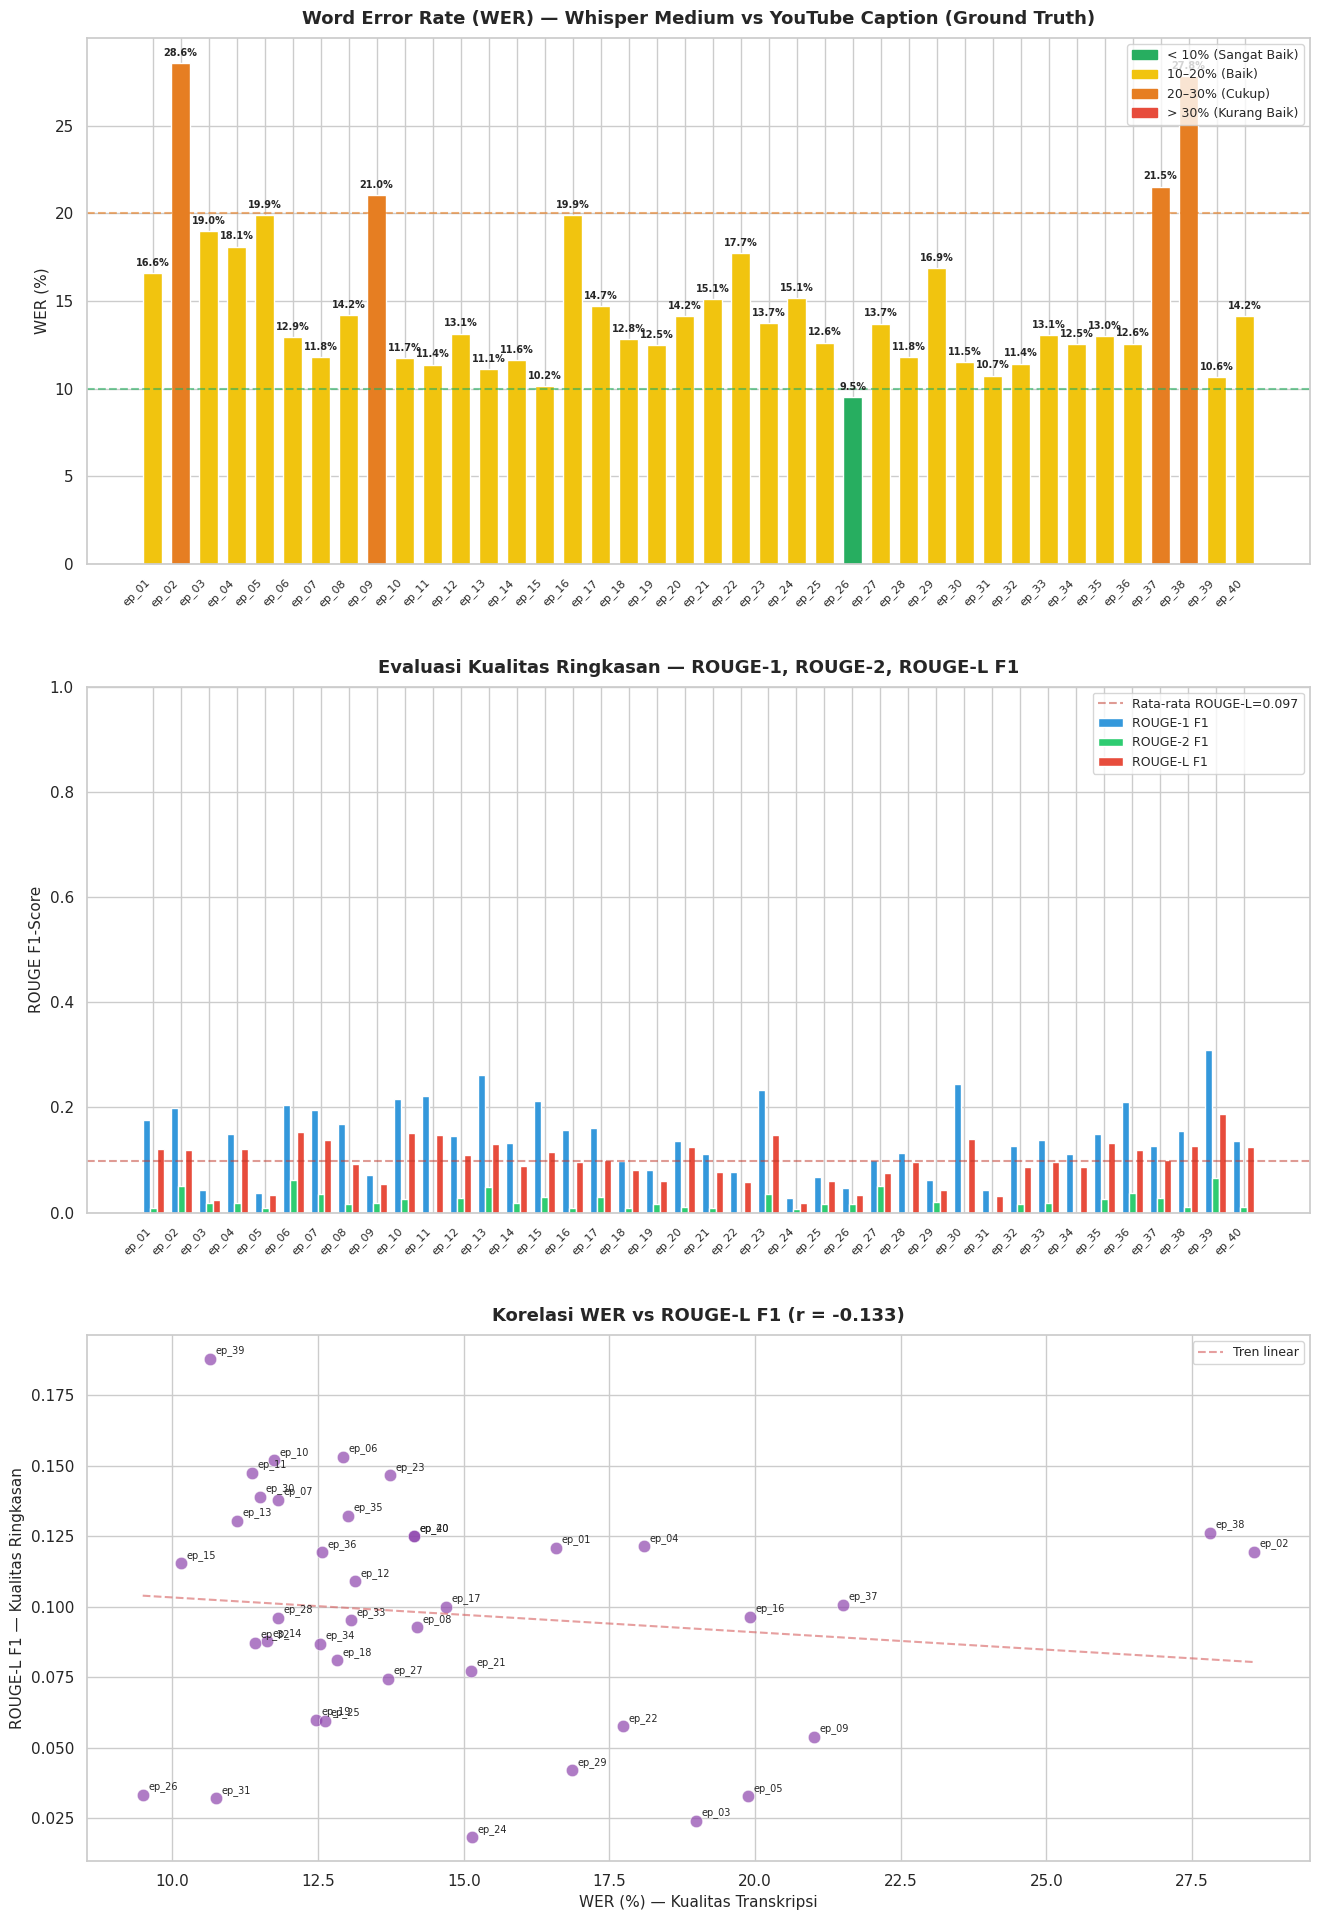


 Grafik disimpan (DPI=300): /content/drive/MyDrive/NLP_SatuPersen/plots/evaluasi_final.png


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np

sns.set_theme(style="whitegrid", palette="muted")

if df_final.empty:
    print("  Tidak ada data untuk divisualisasikan")
else:
    fig, axes = plt.subplots(3, 1, figsize=(14, 20))

    episodes = df_final["Episode"].tolist()
    x = np.arange(len(episodes))

    # === GRAFIK 1: WER per Episode ===
    ax1 = axes[0]
    if 'WER (%)' in df_final.columns:
        wer_vals = df_final["WER (%)"].tolist()
        colors_wer = ['#27ae60' if v<10 else '#f1c40f' if v<20 else '#e67e22' if v<30 else '#e74c3c'
                      for v in wer_vals]
        bars = ax1.bar(x, wer_vals, color=colors_wer, edgecolor='white', width=0.7)
        ax1.axhline(y=10, color='#27ae60', linestyle='--', alpha=0.6, label='Threshold Sangat Baik (10%)')
        ax1.axhline(y=20, color='#e67e22', linestyle='--', alpha=0.6, label='Threshold Cukup (20%)')
        for bar, val in zip(bars, wer_vals):
            ax1.text(bar.get_x()+bar.get_width()/2, val+0.3, f"{val:.1f}%",
                     ha='center', va='bottom', fontsize=7, fontweight='bold')
        ax1.set_title("Word Error Rate (WER) — Whisper Medium vs YouTube Caption (Ground Truth)",
                      fontsize=13, fontweight='bold', pad=10)
        ax1.set_ylabel("WER (%)", fontsize=11)
        legend_patches = [
            mpatches.Patch(color='#27ae60', label='< 10% (Sangat Baik)'),
            mpatches.Patch(color='#f1c40f', label='10–20% (Baik)'),
            mpatches.Patch(color='#e67e22', label='20–30% (Cukup)'),
            mpatches.Patch(color='#e74c3c', label='> 30% (Kurang Baik)'),
        ]
        ax1.legend(handles=legend_patches, loc='upper right', fontsize=9)
    ax1.set_xticks(x)
    ax1.set_xticklabels(episodes, rotation=45, ha='right', fontsize=8)

    # === GRAFIK 2: ROUGE-1, ROUGE-2, ROUGE-L F1 ===
    ax2 = axes[1]
    if all(c in df_final.columns for c in ['ROUGE-1 F1', 'ROUGE-2 F1', 'ROUGE-L F1']):
        w = 0.25
        r1 = df_final['ROUGE-1 F1'].tolist()
        r2 = df_final['ROUGE-2 F1'].tolist()
        rl = df_final['ROUGE-L F1'].tolist()
        ax2.bar(x - w,  r1, w, label='ROUGE-1 F1', color='#3498db', edgecolor='white')
        ax2.bar(x,      r2, w, label='ROUGE-2 F1', color='#2ecc71', edgecolor='white')
        ax2.bar(x + w,  rl, w, label='ROUGE-L F1', color='#e74c3c', edgecolor='white')
        avg_r1 = np.mean(r1)
        avg_rl = np.mean(rl)
        ax2.axhline(y=avg_rl, color='#c0392b', linestyle='--', alpha=0.5,
                    label=f'Rata-rata ROUGE-L={avg_rl:.3f}')
        ax2.set_title("Evaluasi Kualitas Ringkasan — ROUGE-1, ROUGE-2, ROUGE-L F1",
                      fontsize=13, fontweight='bold', pad=10)
        ax2.set_ylabel("ROUGE F1-Score", fontsize=11)
        ax2.set_ylim(0, 1.0)
        ax2.legend(loc='upper right', fontsize=9)
    ax2.set_xticks(x)
    ax2.set_xticklabels(episodes, rotation=45, ha='right', fontsize=8)

    # === GRAFIK 3: Scatter WER vs ROUGE-L (Analisis Korelasi) ===
    ax3 = axes[2]
    if 'WER (%)' in df_final.columns and 'ROUGE-L F1' in df_final.columns:
        wer_v = df_final['WER (%)'].dropna()
        rl_v  = df_final['ROUGE-L F1'][wer_v.index]
        ax3.scatter(wer_v, rl_v, color='#8e44ad', alpha=0.7, s=80, edgecolors='white', linewidths=0.5)
        for i, (ep, wx, rx) in enumerate(zip(df_final['Episode'][wer_v.index], wer_v, rl_v)):
            ax3.annotate(ep, (wx, rx), textcoords='offset points', xytext=(4, 4), fontsize=7)
        # Regresi linear
        if len(wer_v) > 3:
            z = np.polyfit(wer_v, rl_v, 1)
            p = np.poly1d(z)
            xline = np.linspace(wer_v.min(), wer_v.max(), 100)
            ax3.plot(xline, p(xline), 'r--', alpha=0.6, label='Tren linear')
            corr = np.corrcoef(wer_v, rl_v)[0, 1]
            ax3.set_title(f"Korelasi WER vs ROUGE-L F1 (r = {corr:.3f})",
                          fontsize=13, fontweight='bold', pad=10)
        ax3.set_xlabel("WER (%) — Kualitas Transkripsi", fontsize=11)
        ax3.set_ylabel("ROUGE-L F1 — Kualitas Ringkasan", fontsize=11)
        ax3.legend(fontsize=9)

    plt.tight_layout(pad=3.0)
    plot_path = os.path.join(paths['plots'], "evaluasi_final.png")
    plt.savefig(plot_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"\n Grafik disimpan (DPI=300): {plot_path}")